# 🧠 Clasificación Binaria de Tumores Cerebrales en MRI con YOLO
**Trabajo Integrador de Conocimientos 05-2026**  
Universidad Nacional de Tucumán — FACET

---
**Pipeline:** Dataset (Kaggle) → Curación Binaria → Benchmarking YOLO → Métricas → Selección Óptima

## 1. Entorno de Ejecución y Configuración

In [ ]:
import os, json

# Reemplazá con tu usuario de Kaggle y el token que ves en pantalla
os.makedirs('/root/.kaggle', exist_ok=True)

kaggle_config = {
    "username": "TU_USUARIO_DE_KAGGLE",  # ← tu nombre de usuario
    "key": "EL_TOKEN_QUE_VES_EN_PANTALLA"  # ← el que empieza con KGAT_...
}

with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump(kaggle_config, f)

os.chmod('/root/.kaggle/kaggle.json', 0o600)
print('✅ kaggle.json creado correctamente')

✅ kaggle.json creado correctamente


In [ ]:
# --- Verificar GPU ---
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else '⚠️ GPU no disponible — activá Runtime > Change runtime type > T4 GPU')

Tue Jun 30 15:40:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# --- Instalar dependencias ---
!pip install ultralytics kaggle seaborn scikit-learn -q
print('✅ Dependencias instaladas')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 30.5 MB/s eta 0:00:00
✅ Dependencias instaladas


In [ ]:
# --- Verificar versiones ---
import torch
import ultralytics
print(f'PyTorch:      {torch.__version__}')
print(f'Ultralytics:  {ultralytics.__version__}')
print(f'CUDA:         {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU:          {torch.cuda.get_device_name(0)}')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'\n✅ Usando dispositivo: {DEVICE}')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch:      2.11.0+cu128
Ultralytics:  8.4.84
CUDA:         True
GPU:          Tesla T4

✅ Usando dispositivo: cuda


## 2. Dataset y Preparación de Datos
### 2a. Fuente de datos — Descarga desde Kaggle

In [ ]:
# --- Subir kaggle.json ---
# INSTRUCCIÓN: Cuando aparezca el botón, seleccioná el archivo kaggle.json que descargaste
from google.colab import files
import os

print('📂 Seleccioná tu archivo kaggle.json...')
uploaded = files.upload()

os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print('✅ Kaggle API configurada correctamente')

📂 Seleccioná tu archivo kaggle.json...


Saving kaggle.json to kaggle.json
✅ Kaggle API configurada correctamente


In [ ]:
# --- Descargar dataset ---
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d brain_tumor_raw
print('✅ Dataset descargado y descomprimido')

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 134MB/s]

✅ Dataset descargado y descomprimido


In [ ]:
# --- Explorar estructura original ---
from pathlib import Path

raw = Path('brain_tumor_raw')
print('📁 Estructura del dataset original:')
for split in ['Training', 'Testing']:
    split_path = raw / split
    if not split_path.exists():
        continue
    print(f'\n  {split}/')
    total = 0
    for cls in sorted(split_path.iterdir()):
        if cls.is_dir():
            n = len(list(cls.glob('*')))
            total += n
            print(f'    {cls.name}/  →  {n} imágenes')
    print(f'    TOTAL: {total}')

📁 Estructura del dataset original:

  Training/
    glioma/  →  1400 imágenes
    meningioma/  →  1400 imágenes
    notumor/  →  1400 imágenes
    pituitary/  →  1400 imágenes
    TOTAL: 5600

  Testing/
    glioma/  →  400 imágenes
    meningioma/  →  400 imágenes
    notumor/  →  400 imágenes
    pituitary/  →  400 imágenes
    TOTAL: 1600


### 2b-c. Reducción del espacio de clases — Justificación teórica

**Clases originales (4):** glioma · meningioma · notumor · pituitary

**Reducción a clasificación binaria:**
| Clase original | Clase binaria | Justificación |
|---|---|---|
| glioma | **glioma** | Tumor de mayor incidencia y peor pronóstico; target clínico principal |
| meningioma | **no_glioma** | Tumor de origen diferente (meninges); comportamiento clínico distinto |
| pituitary | **no_glioma** | Tumor hipofisario; localización y morfología diferenciada |
| notumor | **no_glioma** | Cerebro sano; ausencia de lesión |

**Criterio clínico:** La detección precoz de gliomas es prioritaria dado su naturaleza infiltrativa y alta mortalidad asociada.

### 2d. Curación manual del dataset

In [ ]:
# --- Reestructurar a clasificación binaria ---
import shutil
import random
from pathlib import Path

random.seed(42)  # Reproducibilidad

raw          = Path('brain_tumor_raw')
train_src    = raw / 'Training'
test_src     = raw / 'Testing'
dest         = Path('brain_tumor_binary')

# Mapeo de 4 clases → 2 clases
BINARY_MAP = {
    'glioma':     'glioma',
    'meningioma': 'no_glioma',
    'notumor':    'no_glioma',
    'pituitary':  'no_glioma',
}

VAL_RATIO = 0.20  # 20% de Training → validación

# Crear estructura de carpetas
for split in ['train', 'val', 'test']:
    for cls in ['glioma', 'no_glioma']:
        (dest / split / cls).mkdir(parents=True, exist_ok=True)

def get_images(folder):
    exts = ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']
    imgs = []
    for ext in exts:
        imgs.extend(folder.glob(ext))
    return imgs

# Procesar Training → train + val
print('📂 Procesando Training → train / val (80/20)...')
for orig_cls, bin_cls in BINARY_MAP.items():
    src = train_src / orig_cls
    if not src.exists():
        print(f'  ⚠️  No encontrado: {src}')
        continue
    imgs = get_images(src)
    random.shuffle(imgs)
    cut = int(len(imgs) * (1 - VAL_RATIO))
    for img in imgs[:cut]:
        dst = dest / 'train' / bin_cls / f'{orig_cls}_{img.name}'
        shutil.copy2(img, dst)
    for img in imgs[cut:]:
        dst = dest / 'val' / bin_cls / f'{orig_cls}_{img.name}'
        shutil.copy2(img, dst)
    print(f'  {orig_cls:12s} → {bin_cls}: {cut} train | {len(imgs)-cut} val')

# Procesar Testing → test
print('\n📂 Procesando Testing → test...')
for orig_cls, bin_cls in BINARY_MAP.items():
    src = test_src / orig_cls
    if not src.exists():
        continue
    imgs = get_images(src)
    for img in imgs:
        dst = dest / 'test' / bin_cls / f'{orig_cls}_{img.name}'
        shutil.copy2(img, dst)
    print(f'  {orig_cls:12s} → {bin_cls}: {len(imgs)} test')

print('\n✅ Reestructuración completada')

📂 Procesando Training → train / val (80/20)...
  glioma       → glioma: 1120 train | 280 val
  meningioma   → no_glioma: 1120 train | 280 val
  notumor      → no_glioma: 1120 train | 280 val
  pituitary    → no_glioma: 1120 train | 280 val

📂 Procesando Testing → test...
  glioma       → glioma: 400 test
  meningioma   → no_glioma: 400 test
  notumor      → no_glioma: 400 test
  pituitary    → no_glioma: 400 test

✅ Reestructuración completada


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2e. Validación del dataset

In [ ]:
# --- Resumen cuantitativo + validación de integridad ---
from PIL import Image
from pathlib import Path

dest = Path('brain_tumor_binary')
print('📊 DISTRIBUCIÓN FINAL DEL DATASET BINARIO')
print('-' * 45)

grand_total = 0
corrupt = []

for split in ['train', 'val', 'test']:
    print(f'\n  {split.upper()}:')
    split_total = 0
    for cls in ['glioma', 'no_glioma']:
        folder = dest / split / cls
        imgs = list(folder.glob('*'))
        count = len(imgs)
        split_total += count
        grand_total += count
        # Verificar integridad de muestra (primeras 20)
        for p in imgs[:20]:
            try:
                Image.open(p).verify()
            except:
                corrupt.append(str(p))
        print(f'    {cls:12s}: {count:5d} imágenes')
    print(f'    {"SUBTOTAL":12s}: {split_total:5d}')

print(f'\n  TOTAL DATASET: {grand_total} imágenes')
print('-' * 45)

if corrupt:
    print(f'⚠️  Imágenes corruptas detectadas: {len(corrupt)}')
    for c in corrupt:
        print(f'   {c}')
else:
    print('✅ Validación de integridad: sin imágenes corruptas')

📊 DISTRIBUCIÓN FINAL DEL DATASET BINARIO
---------------------------------------------

  TRAIN:
    glioma      :  1120 imágenes
    no_glioma   :  3360 imágenes
    SUBTOTAL    :  4480

  VAL:
    glioma      :   280 imágenes
    no_glioma   :   840 imágenes
    SUBTOTAL    :  1120

  TEST:
    glioma      :   400 imágenes
    no_glioma   :  1200 imágenes
    SUBTOTAL    :  1600

  TOTAL DATASET: 7200 imágenes
---------------------------------------------
✅ Validación de integridad: sin imágenes corruptas


## 3. Arquitecturas Evaluadas

| Modelo | Parámetros (M) | Familia | Característica |
|---|---|---|---|
| **YOLOv8n-cls** | ~2.7M | YOLOv8 | Nano — velocidad máxima |
| **YOLOv8s-cls** | ~6.4M | YOLOv8 | Small — balance velocidad/precisión |
| **YOLO11n-cls** | ~2.6M | YOLO11 | Nano última generación — arquitectura mejorada |

Las tres variantes son entrenadas bajo las mismas condiciones para garantizar comparación justa (benchmarking controlado).

## 4. Preparación del Dataset para Entrenamiento

In [ ]:
# --- Verificar estructura lista para YOLO ---
from pathlib import Path

DATA_PATH = 'brain_tumor_binary'
dest = Path(DATA_PATH)

print('📁 Estructura requerida por Ultralytics YOLO (classify):')
ok = True
for split in ['train', 'val', 'test']:
    for cls in ['glioma', 'no_glioma']:
        p = dest / split / cls
        n = len(list(p.glob('*')))
        status = '✅' if n > 0 else '❌'
        print(f'  {status} {DATA_PATH}/{split}/{cls}/  ({n} imgs)')
        if n == 0:
            ok = False

print()
print('✅ Dataset listo para entrenamiento' if ok else '❌ Revisar estructura')

📁 Estructura requerida por Ultralytics YOLO (classify):
  ✅ brain_tumor_binary/train/glioma/  (1120 imgs)
  ✅ brain_tumor_binary/train/no_glioma/  (3360 imgs)
  ✅ brain_tumor_binary/val/glioma/  (280 imgs)
  ✅ brain_tumor_binary/val/no_glioma/  (840 imgs)
  ✅ brain_tumor_binary/test/glioma/  (400 imgs)
  ✅ brain_tumor_binary/test/no_glioma/  (1200 imgs)

✅ Dataset listo para entrenamiento


## 5. Proceso de Entrenamiento
### 5a-b. Hiperparámetros y Estrategia

In [ ]:
# --- Configuración global de hiperparámetros ---
HYPERPARAMS = {
    'epochs':     25,      # Épocas de entrenamiento
    'imgsz':      224,     # Tamaño de imagen (224x224)
    'batch':      32,      # Batch size
    'optimizer':  'Adam',  # Optimizador
    'lr0':        0.001,   # Learning rate inicial
    'dropout':    0.2,     # Dropout para regularización
    'patience':   10,      # Early stopping
    'workers':    2,       # Colab: usar 2 workers
    'seed':       42,      # Reproducibilidad
    'pretrained': True,    # Transfer learning (ImageNet)
}

# Modelos a evaluar en el benchmarking
MODELS = [
    {'name': 'yolov8n', 'weights': 'yolov8n-cls.pt'},
    {'name': 'yolov8s', 'weights': 'yolov8s-cls.pt'},
    {'name': 'yolo11n', 'weights': 'yolo11n-cls.pt'},
]

print('📋 Configuración de Entrenamiento:')
for k, v in HYPERPARAMS.items():
    print(f'  {k:12s}: {v}')
print(f'\n🏗️  Modelos a evaluar: {[m["name"] for m in MODELS]}')

📋 Configuración de Entrenamiento:
  epochs      : 25
  imgsz       : 224
  batch       : 32
  optimizer   : Adam
  lr0         : 0.001
  dropout     : 0.2
  patience    : 10
  workers     : 2
  seed        : 42
  pretrained  : True

🏗️  Modelos a evaluar: ['yolov8n', 'yolov8s', 'yolo11n']


In [ ]:
# =====================================================================
# ENTRENAMIENTO — Este bloque tarda ~15-25 min en T4 GPU
# Ejecutar y no cerrar el navegador
# =====================================================================
from ultralytics import YOLO
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
training_results = {}

for cfg in MODELS:
    print(f"\n{'='*55}")
    print(f"🚀 Entrenando: {cfg['name']}  |  Pesos: {cfg['weights']}")
    print(f"{'='*55}")

    model = YOLO(cfg['weights'])

    result = model.train(
        data        = DATA_PATH,
        epochs      = HYPERPARAMS['epochs'],
        imgsz       = HYPERPARAMS['imgsz'],
        batch       = HYPERPARAMS['batch'],
        optimizer   = HYPERPARAMS['optimizer'],
        lr0         = HYPERPARAMS['lr0'],
        dropout     = HYPERPARAMS['dropout'],
        patience    = HYPERPARAMS['patience'],
        workers     = HYPERPARAMS['workers'],
        seed        = HYPERPARAMS['seed'],
        pretrained  = HYPERPARAMS['pretrained'],
        device      = DEVICE,
        project     = 'runs/classify',
        name        = cfg['name'],
        exist_ok    = True,
        verbose     = False,
    )

    rd = result.results_dict
    training_results[cfg['name']] = {
        'weights': cfg['weights'],
        'top1':    rd.get('metrics/accuracy_top1', 0),
        'top5':    rd.get('metrics/accuracy_top5', 0),
        'result':  result,
    }
    print(f"\n  ✅ {cfg['name']} — Top-1 Accuracy: {training_results[cfg['name']]['top1']:.4f}")

print("\n\n🏁 Entrenamiento de todos los modelos completado")


🚀 Entrenando: yolov8n  |  Pesos: yolov8n-cls.pt
Ultralytics 8.4.83 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=brain_tumor_binary, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.2, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=False, opset=None, optimize=False, op

## 6. Extracción y Procesamiento de Métricas

In [ ]:
import os
# Buscar todos los results.csv en el sistema
for root, dirs, files in os.walk('/content'):
    for f in files:
        if f == 'results.csv' or f == 'best.pt':
            print(os.path.join(root, f))

/content/runs/classify/runs/classify/yolo11n/results.csv
/content/runs/classify/runs/classify/yolo11n/weights/best.pt
/content/runs/classify/runs/classify/yolov8n/results.csv
/content/runs/classify/runs/classify/yolov8n/weights/best.pt
/content/runs/classify/runs/classify/yolov8s/results.csv
/content/runs/classify/runs/classify/yolov8s/weights/best.pt


In [ ]:
# --- Cargar results.csv de cada run ---
import pandas as pd
from pathlib import Path

# Path correcto (duplicado)
BASE = Path('/content/runs/classify/runs/classify')
MODEL_NAMES = ['yolov8n', 'yolov8s', 'yolo11n']

run_dfs = {}
for name in MODEL_NAMES:
    csv_path = BASE / name / 'results.csv'
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()
        run_dfs[name] = df
        print(f'✅ {name}: {len(df)} épocas — columnas: {list(df.columns)}')
    else:
        print(f'❌ {name}: no encontrado en {csv_path}')

✅ yolov8n: 25 épocas — columnas: ['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'metrics/accuracy_top5', 'val/loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
✅ yolov8s: 19 épocas — columnas: ['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'metrics/accuracy_top5', 'val/loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
✅ yolo11n: 25 épocas — columnas: ['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'metrics/accuracy_top5', 'val/loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


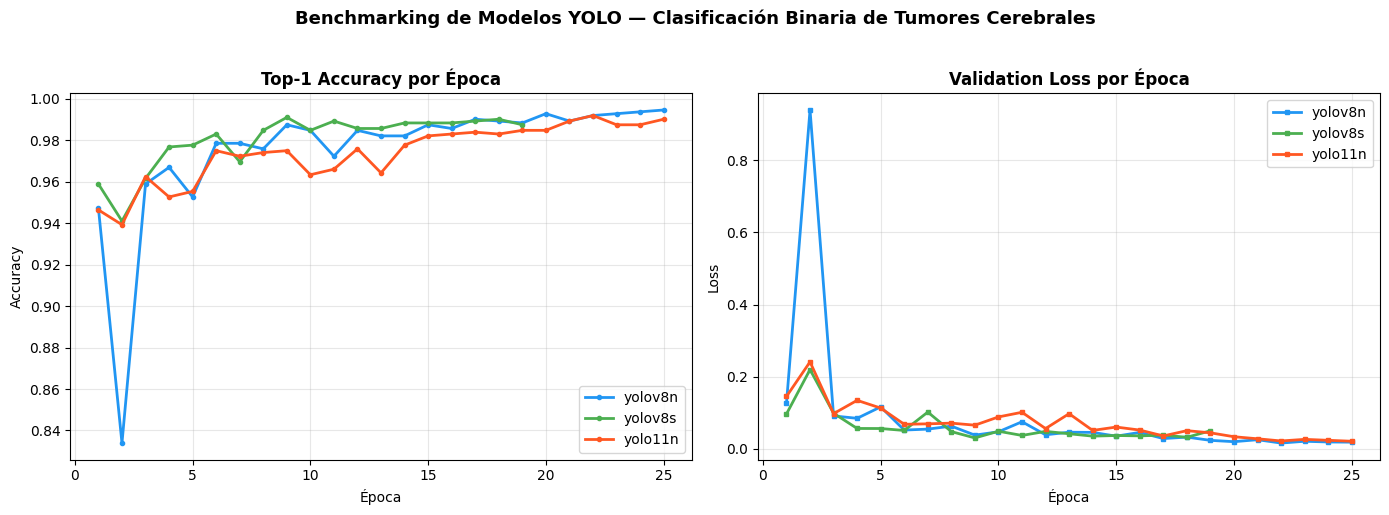

✅ Gráfico guardado: training_comparison.png


In [ ]:
# --- Graficar Accuracy y Loss por época ---
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

COLORS = {'yolov8n': '#2196F3', 'yolov8s': '#4CAF50', 'yolo11n': '#FF5722'}

def find_col(df, keywords):
    """Encuentra la columna que contiene las keywords"""
    for col in df.columns:
        if all(k.lower() in col.lower() for k in keywords):
            return col
    return None

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Benchmarking de Modelos YOLO — Clasificación Binaria de Tumores Cerebrales',
             fontsize=13, fontweight='bold', y=1.02)

for name, df in run_dfs.items():
    color = COLORS.get(name, 'gray')
    epoch_col = find_col(df, ['epoch']) or df.columns[0]

    # Accuracy
    acc_col = find_col(df, ['accuracy', 'top1']) or find_col(df, ['acc'])
    if acc_col:
        axes[0].plot(df[epoch_col], df[acc_col], label=name,
                     color=color, linewidth=2, marker='o', markersize=3)

    # Validation Loss
    loss_col = find_col(df, ['val', 'loss']) or find_col(df, ['loss'])
    if loss_col:
        axes[1].plot(df[epoch_col], df[loss_col], label=name,
                     color=color, linewidth=2, marker='s', markersize=3)

for ax, title, ylabel in zip(
    axes,
    ['Top-1 Accuracy por Época', 'Validation Loss por Época'],
    ['Accuracy', 'Loss']
):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Época')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Gráfico guardado: training_comparison.png')

## 7. Evaluación del Desempeño
### 7a-b. Análisis cuantitativo y Comparación entre modelos

In [ ]:
# --- Tabla comparativa ---
import pandas as pd
from pathlib import Path

rows = []
for name in MODEL_NAMES:
    df = run_dfs.get(name)
    if df is None:
        continue

    # Buscar columnas de accuracy y loss
    acc_col  = find_col(df, ['accuracy', 'top1']) or find_col(df, ['acc'])
    loss_col = find_col(df, ['val', 'loss'])

    best_acc   = df[acc_col].max()   if acc_col  else 0
    final_loss = df[loss_col].iloc[-1] if loss_col else 0
    best_epoch = int(df[acc_col].idxmax() + 1) if acc_col else 0

    # Tamaño del modelo
    w_path = Path(f'runs/classify/{name}/weights/best.pt')
    size_mb = round(w_path.stat().st_size / 1e6, 1) if w_path.exists() else 0

    rows.append({
        'Modelo':              name,
        'Mejor Acc (Top-1)':   f'{best_acc:.4f}',
        'Val Loss Final':      f'{final_loss:.4f}',
        'Mejor Época':         best_epoch,
        'Épocas Totales':      len(df),
        'Tamaño (MB)':         size_mb,
    })

comp_df = pd.DataFrame(rows)
print('📊 TABLA COMPARATIVA DE MODELOS')
print('=' * 65)
print(comp_df.to_string(index=False))
print('=' * 65)

# Identificar mejor modelo
best_row = comp_df.loc[comp_df['Mejor Acc (Top-1)'].astype(float).idxmax()]
BEST_MODEL = best_row['Modelo']
print(f'\n🏆 Mejor modelo: {BEST_MODEL}  (Accuracy = {best_row["Mejor Acc (Top-1)"]})')

📊 TABLA COMPARATIVA DE MODELOS
 Modelo Mejor Acc (Top-1) Val Loss Final  Mejor Época  Épocas Totales  Tamaño (MB)
yolov8n            0.9946         0.0189           25              25            0
yolov8s            0.9911         0.0504            9              19            0
yolo11n            0.9920         0.0214           22              25            0

🏆 Mejor modelo: yolov8n  (Accuracy = 0.9946)


## 8. Selección y Validación del Modelo Óptimo

In [ ]:
# --- Cargar el mejor modelo y evaluar en test set ---
from ultralytics import YOLO
from pathlib import Path

# Path correcto
BASE = Path('/content/runs/classify/runs/classify')
BEST_MODEL = max(MODEL_NAMES, key=lambda n: run_dfs[n].iloc[-1]['metrics/accuracy_top1'] if n in run_dfs else 0)

best_weights = BASE / BEST_MODEL / 'weights' / 'best.pt'
print(f'📌 Mejor modelo seleccionado: {BEST_MODEL}')
print(f'📌 Pesos: {best_weights}')

best_model = YOLO(str(best_weights))

# Validación en test set
val_results = best_model.val(
    data    = DATA_PATH,
    split   = 'test',
    verbose = True,
)

print(f'\n✅ Resultados en Test Set:')
print(f'   Top-1 Accuracy: {val_results.results_dict.get("metrics/accuracy_top1", 0):.4f}')
print(f'   Top-5 Accuracy: {val_results.results_dict.get("metrics/accuracy_top5", 0):.4f}')

📌 Mejor modelo seleccionado: yolov8n
📌 Pesos: /content/runs/classify/runs/classify/yolov8n/weights/best.pt
Ultralytics 8.4.83 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /content/brain_tumor_binary/train... found 4480 images in 2 classes ✅ 
val: /content/brain_tumor_binary/val... found 1120 images in 2 classes ✅ 
test: /content/brain_tumor_binary/test... found 1600 images in 2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1067.9±444.0 MB/s, size: 22.4 KB)
test: Scanning /content/brain_tumor_binary/test... 1600 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1600/1600 5.6Kit/s 0.3s
test: New cache created: /content/brain_tumor_binary/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 100/100 12.0it/s 8.4s
                   all      0.956          1
Speed: 0.1ms preprocess, 0.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to 

⏳ Generando predicciones en test set...
  Procesando glioma: 400 imágenes
  Procesando no_glioma: 1200 imágenes


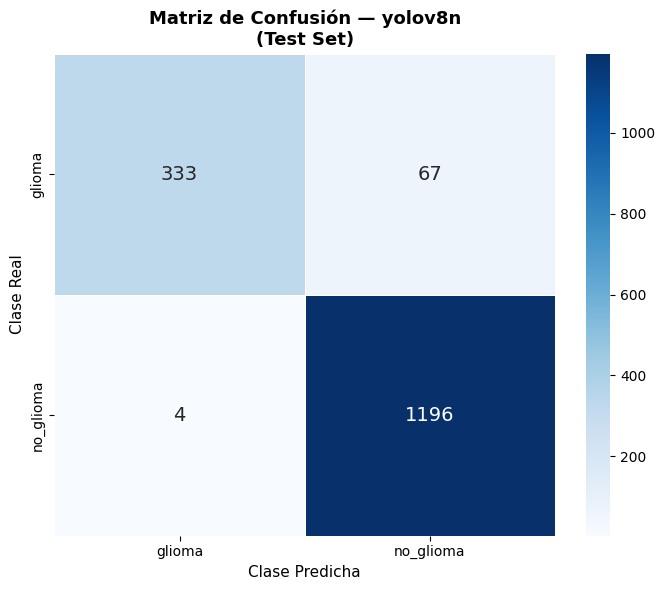


📋 REPORTE DE CLASIFICACIÓN:
              precision    recall  f1-score   support

      glioma     0.9881    0.8325    0.9037       400
   no_glioma     0.9470    0.9967    0.9712      1200

    accuracy                         0.9556      1600
   macro avg     0.9675    0.9146    0.9374      1600
weighted avg     0.9572    0.9556    0.9543      1600



In [ ]:
# --- Matriz de Confusión + Classification Report ---
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

CLASSES = ['glioma', 'no_glioma']
test_path = Path('brain_tumor_binary/test')

y_true, y_pred = [], []
print('⏳ Generando predicciones en test set...')

for cls_idx, cls_name in enumerate(CLASSES):
    cls_path = test_path / cls_name
    imgs = list(cls_path.glob('*'))
    print(f'  Procesando {cls_name}: {len(imgs)} imágenes')
    for img_path in imgs:
        res = best_model.predict(str(img_path), verbose=False)
        pred = res[0].probs.top1
        y_true.append(cls_idx)
        y_pred.append(pred)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            linewidths=0.5, ax=ax, annot_kws={'size': 14})
ax.set_title(f'Matriz de Confusión — {BEST_MODEL}\n(Test Set)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Clase Real', fontsize=11)
ax.set_xlabel('Clase Predicha', fontsize=11)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Report
print('\n📋 REPORTE DE CLASIFICACIÓN:')
print('=' * 55)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

Aciertos: 96 | Errores: 4


/tmp/ipykernel_828/1697244367.py:49: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_828/1697244367.py:49: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_828/1697244367.py:50: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
/tmp/ipykernel_828/1697244367.py:50: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu S

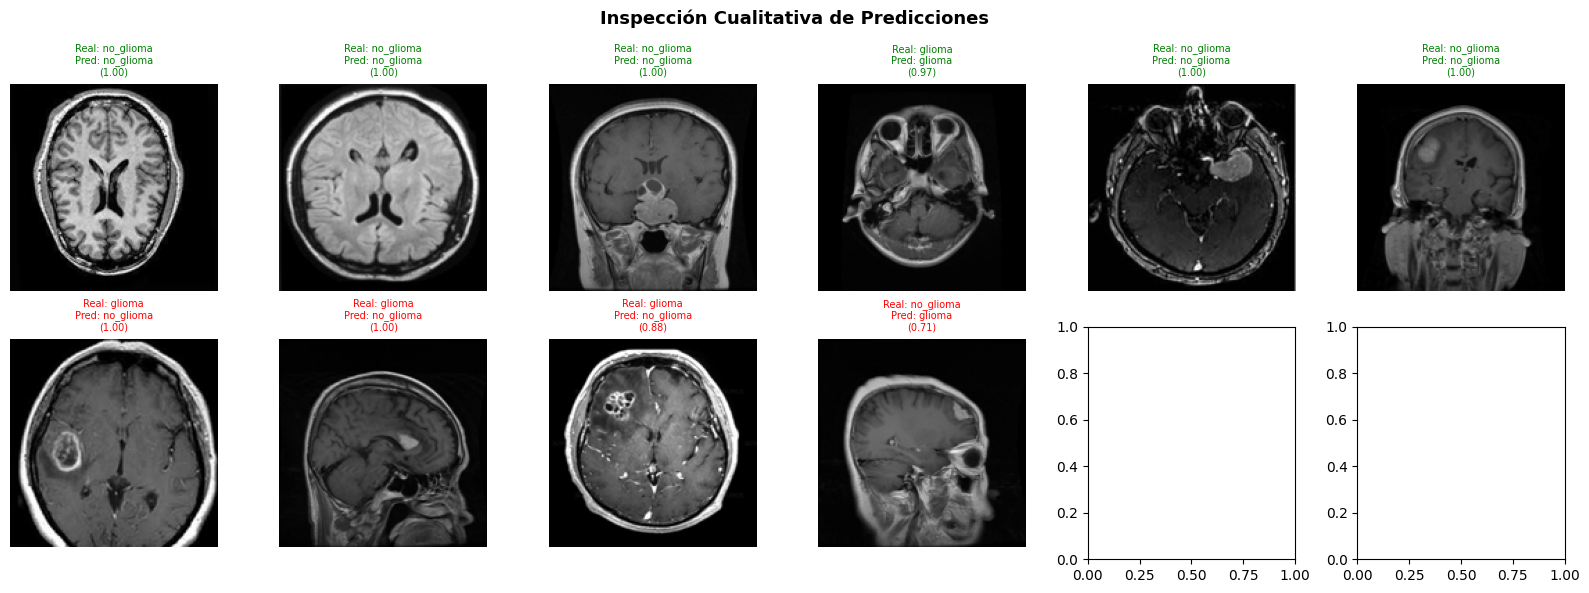

✅ Guardado: sample_predictions.png


In [ ]:
# --- Inspección cualitativa: muestra de predicciones correctas e incorrectas ---
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import numpy as np
from pathlib import Path
import random

CLASSES = ['glioma', 'no_glioma']
test_path = Path('brain_tumor_binary/test')

# Recolectar errores y aciertos
errors, correct = [], []
random.seed(42)

all_imgs = []
for ci, cls in enumerate(CLASSES):
    for p in (test_path / cls).glob('*'):
        all_imgs.append((p, ci))

random.shuffle(all_imgs)
for img_path, true_ci in all_imgs[:100]:  # Evaluar muestra
    res = best_model.predict(str(img_path), verbose=False)
    pred = res[0].probs.top1
    conf = res[0].probs.top1conf.item()
    entry = (img_path, CLASSES[true_ci], CLASSES[pred], conf)
    (errors if pred != true_ci else correct).append(entry)

print(f'Aciertos: {len(correct)} | Errores: {len(errors)}')

# Visualizar
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle('Inspección Cualitativa de Predicciones', fontsize=13, fontweight='bold')

for row, (sample, label) in enumerate([
    (correct[:6], '✅ Correctas'),
    (errors[:6],  '❌ Incorrectas')
]):
    for col, (img_path, true_cls, pred_cls, conf) in enumerate(sample):
        ax = axes[row][col]
        img = Image.open(img_path).convert('RGB').resize((150, 150))
        ax.imshow(np.array(img), cmap='gray')
        color = 'green' if row == 0 else 'red'
        ax.set_title(f'Real: {true_cls}\nPred: {pred_cls}\n({conf:.2f})',
                     fontsize=7, color=color)
        ax.axis('off')
    axes[row][0].set_ylabel(label, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Guardado: sample_predictions.png')

In [ ]:
# --- Resumen ejecutivo final ---
print('=' * 60)
print('         RESUMEN EJECUTIVO — TRABAJO INTEGRADOR')
print('=' * 60)
print(f'\n  Dataset:         Brain Tumor MRI (masoudnickparvar)')
print(f'  Clases:          glioma | no_glioma (binaria)')
print(f'  Modelos:         YOLOv8n-cls · YOLOv8s-cls · YOLO11n-cls')
print(f'  Épocas:          {HYPERPARAMS["epochs"]}')
print(f'  Imagen:          {HYPERPARAMS["imgsz"]}x{HYPERPARAMS["imgsz"]} px')
print(f'  Batch:           {HYPERPARAMS["batch"]}')
print(f'  Optimizador:     {HYPERPARAMS["optimizer"]} (lr={HYPERPARAMS["lr0"]})')
print(f'  Transfer Learn.: Pesos ImageNet (pretrained=True)')
print()
print('  COMPARATIVA:')
print(comp_df.to_string(index=False))
print()
print(f'  MODELO ÓPTIMO:   {BEST_MODEL}')
print(f'  ACCURACY:        {best_row["Mejor Acc (Top-1)"]}')
print('=' * 60)

         RESUMEN EJECUTIVO — TRABAJO INTEGRADOR

  Dataset:         Brain Tumor MRI (masoudnickparvar)
  Clases:          glioma | no_glioma (binaria)
  Modelos:         YOLOv8n-cls · YOLOv8s-cls · YOLO11n-cls
  Épocas:          25
  Imagen:          224x224 px
  Batch:           32
  Optimizador:     Adam (lr=0.001)
  Transfer Learn.: Pesos ImageNet (pretrained=True)

  COMPARATIVA:
 Modelo Mejor Acc (Top-1) Val Loss Final  Mejor Época  Épocas Totales  Tamaño (MB)
yolov8n            0.9946         0.0189           25              25            0
yolov8s            0.9911         0.0504            9              19            0
yolo11n            0.9920         0.0214           22              25            0

  MODELO ÓPTIMO:   yolov8n
  ACCURACY:        0.9946


In [ ]:
# --- Descargar todos los archivos generados ---
from google.colab import files
import os

outputs = [
    'training_comparison.png',
    'confusion_matrix.png',
    'sample_predictions.png',
]

for f in outputs:
    if os.path.exists(f):
        files.download(f)
        print(f'⬇️  Descargando: {f}')

# También descargar best weights
best_pt = f'/content/runs/classify/runs/classify/{BEST_MODEL}/weights/best.pt'
if os.path.exists(best_pt):
    files.download(best_pt)
    print(f'⬇️  Descargando: best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️  Descargando: training_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

⬇️  Descargando: sample_predictions.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️  Descargando: best.pt


# 10. Testing con dataset externo

In [ ]:
# =====================================================================
# EVALUACIÓN EN DATASET EXTERNO (sin reentrenar)
# Dataset: bilalakgz/brain-tumor-mri-dataset
# =====================================================================
!kaggle datasets download -d bilalakgz/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d external_raw
print('✅ Dataset externo descargado')

Dataset URL: https://www.kaggle.com/datasets/bilalakgz/brain-tumor-mri-dataset
License(s): MIT
100% 92.1M/92.1M [00:00<00:00, 128MB/s]

✅ Dataset externo descargado


In [ ]:
from pathlib import Path

# Apuntamos directo a la carpeta de clasificación, ignorando la de segmentación
CLASS_ROOT = Path('external_raw/brain_tumor_dataset/brain_tumor_classification')

TARGET_CLASSES = ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']

found_folders = {}
for cls in TARGET_CLASSES:
    matches = [p for p in CLASS_ROOT.rglob('*') if p.is_dir() and p.name.lower() == cls]
    if matches:
        found_folders[cls] = matches

print('📁 Carpetas encontradas:')
for cls, paths in found_folders.items():
    for p in paths:
        n = len(list(p.glob('*')))
        print(f'  {cls:18s} → {p}  ({n} imgs)')

📁 Carpetas encontradas:
  glioma_tumor       → external_raw/brain_tumor_dataset/brain_tumor_classification/Testing/glioma_tumor  (100 imgs)
  glioma_tumor       → external_raw/brain_tumor_dataset/brain_tumor_classification/Training/glioma_tumor  (826 imgs)
  meningioma_tumor   → external_raw/brain_tumor_dataset/brain_tumor_classification/Testing/meningioma_tumor  (115 imgs)
  meningioma_tumor   → external_raw/brain_tumor_dataset/brain_tumor_classification/Training/meningioma_tumor  (822 imgs)
  no_tumor           → external_raw/brain_tumor_dataset/brain_tumor_classification/Testing/no_tumor  (105 imgs)
  no_tumor           → external_raw/brain_tumor_dataset/brain_tumor_classification/Training/no_tumor  (395 imgs)
  pituitary_tumor    → external_raw/brain_tumor_dataset/brain_tumor_classification/Testing/pituitary_tumor  (74 imgs)
  pituitary_tumor    → external_raw/brain_tumor_dataset/brain_tumor_classification/Training/pituitary_tumor  (827 imgs)


In [ ]:
from pathlib import Path

EXTERNAL_RAW = Path('external_raw')

print('📁 Estructura completa del dataset externo:')
for p in sorted(EXTERNAL_RAW.rglob('*')):
    if p.is_dir():
        n_files = len([f for f in p.iterdir() if f.is_file()])
        depth = len(p.relative_to(EXTERNAL_RAW).parts)
        indent = '  ' * depth
        print(f'{indent}{p.name}/  ({n_files} archivos)')

📁 Estructura completa del dataset externo:
  brain_tumor_dataset/  (0 archivos)
    brain_tumor_classification/  (0 archivos)
      Testing/  (0 archivos)
        glioma_tumor/  (100 archivos)
        meningioma_tumor/  (115 archivos)
        no_tumor/  (105 archivos)
        pituitary_tumor/  (74 archivos)
      Training/  (0 archivos)
        glioma_tumor/  (826 archivos)
        meningioma_tumor/  (822 archivos)
        no_tumor/  (395 archivos)
        pituitary_tumor/  (827 archivos)
    brain_tumor_segmentation/  (3 archivos)
      test/  (0 archivos)
        images/  (15 archivos)
        labels/  (15 archivos)
      train/  (0 archivos)
        images/  (102 archivos)
        labels/  (102 archivos)
      valid/  (0 archivos)
        images/  (30 archivos)
        labels/  (30 archivos)


In [ ]:
!pip install ultralytics kaggle seaborn scikit-learn -q
print('✅ Dependencias reinstaladas')

✅ Dependencias reinstaladas


In [ ]:
from google.colab import files
from ultralytics import YOLO
import shutil, os

print('📂 Seleccioná el archivo best.pt...')
uploaded = files.upload()

# Tomamos el nombre del archivo subido (por si no se llama exactamente "best.pt")
uploaded_filename = list(uploaded.keys())[0]

# Lo movemos a una ubicación fija y clara
os.makedirs('/content/best_model_weights', exist_ok=True)
shutil.move(uploaded_filename, '/content/best_model_weights/best.pt')

best_model = YOLO('/content/best_model_weights/best.pt')
BEST_MODEL = 'yolov8n'

print('✅ Modelo recargado correctamente desde el archivo subido')

📂 Seleccioná el archivo best.pt...


Saving besttuned.pt to besttuned.pt
✅ Modelo recargado correctamente desde el archivo subido


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

BINARY_MAP = {
    'glioma_tumor':     'glioma',
    'meningioma_tumor': 'no_glioma',
    'no_tumor':         'no_glioma',
    'pituitary_tumor':  'no_glioma',
}
CLASSES = ['glioma', 'no_glioma']

all_imgs = []
for cls, paths in found_folders.items():
    bin_cls = BINARY_MAP[cls]
    bin_idx = CLASSES.index(bin_cls)
    for folder in paths:
        for img in folder.glob('*'):
            if img.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                all_imgs.append((img, bin_idx))

print(f'📊 Total imágenes externas a evaluar: {len(all_imgs)}')

y_true, y_pred = [], []
for img_path, true_idx in all_imgs:
    res = best_model.predict(str(img_path), verbose=False)
    y_pred.append(res[0].probs.top1)
    y_true.append(true_idx)

acc = accuracy_score(y_true, y_pred)
print(f'\n✅ Accuracy en dataset EXTERNO: {acc:.4f}')
print('\n📋 Reporte de clasificación (dataset externo):')
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

📊 Total imágenes externas a evaluar: 3264

✅ Accuracy en dataset EXTERNO: 0.9758

📋 Reporte de clasificación (dataset externo):
              precision    recall  f1-score   support

      glioma     0.9907    0.9233    0.9558       926
   no_glioma     0.9704    0.9966    0.9833      2338

    accuracy                         0.9758      3264
   macro avg     0.9806    0.9600    0.9696      3264
weighted avg     0.9762    0.9758    0.9755      3264



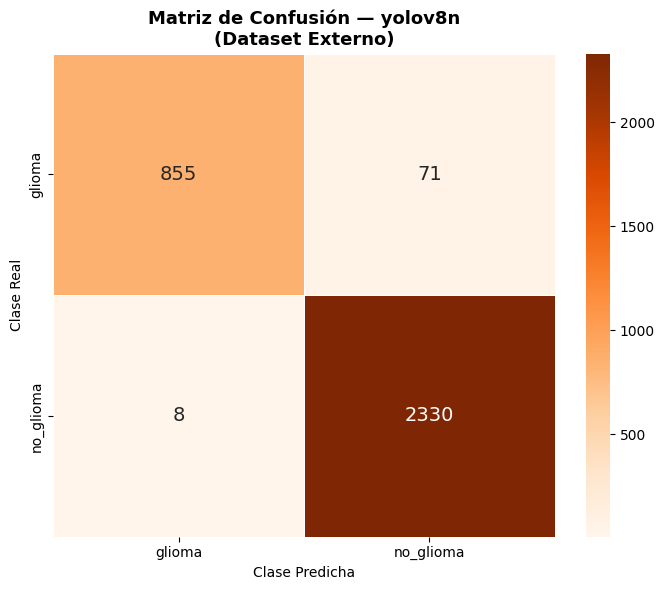

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm_ext = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_ext, annot=True, fmt='d', cmap='Oranges',
            xticklabels=CLASSES, yticklabels=CLASSES,
            linewidths=0.5, ax=ax, annot_kws={'size': 14})
ax.set_title(f'Matriz de Confusión — {BEST_MODEL}\n(Dataset Externo)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Clase Real')
ax.set_xlabel('Clase Predicha')
plt.tight_layout()
plt.savefig('confusion_matrix_external.png', dpi=150, bbox_inches='tight')
plt.show()


# **11 TUNING**

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch

# Ruta al dataset binario
DATA_PATH = "/content/brain_tumor_binary"

# Ruta al mejor peso ya entrenado
BEST_PT = "/content/best_model_weights/best.pt"

# Detectar GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Dispositivo:", DEVICE)
print("Usando pesos:", BEST_PT)

# Cargar modelo ya entrenado
model_tuned = YOLO(BEST_PT)

# Tuning conservador
results_tuned = model_tuned.train(
    data=DATA_PATH,
    epochs=15,
    imgsz=320,
    batch=16,
    lr0=0.0003,
    optimizer="AdamW",
    dropout=0.2,
    patience=5,
    seed=42,
    device=DEVICE,
    name="yolov8n_tuned_img320_lr0003"
)

Dispositivo: 0
Usando pesos: /content/best_model_weights/best.pt
Ultralytics 8.4.83 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/brain_tumor_binary, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.2, dynamic=False, embed=None, end2end=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/best_model_weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_tu

In [ ]:
from ultralytics import YOLO
from pathlib import Path
from sklearn.metrics import accuracy_score

TUNED_PT = "/content/runs/classify/yolov8n_tuned_img320_lr0003/weights/best.pt"

DATA_PATH = "/content/brain_tumor_binary"

model_tuned_eval = YOLO(TUNED_PT)

test_dir = Path(DATA_PATH) / "test"

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

paths = []
y_true = []

for class_folder in test_dir.iterdir():
    if class_folder.is_dir():
        true_class = class_folder.name
        for img_path in class_folder.rglob("*"):
            if img_path.suffix.lower() in IMG_EXTS:
                paths.append(str(img_path))
                y_true.append(true_class)

print("Imágenes evaluadas:", len(paths))

y_pred = []

for result in model_tuned_eval.predict(
    source=paths,
    stream=True,
    verbose=False,
    save=False
):
    pred_idx = int(result.probs.top1)
    pred_class = model_tuned_eval.names[pred_idx]
    y_pred.append(pred_class)

accuracy = accuracy_score(y_true, y_pred)

print("Accuracy tuned:", accuracy)
print("Accuracy tuned %:", accuracy * 100)

Imágenes evaluadas: 1600
Accuracy tuned: 0.959375
Accuracy tuned %: 95.9375


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

best_model = YOLO('/content/runs/classify/yolov8n_tuned_img320_lr0003/weights/best.pt')
BEST_MODEL = 'yolov8n'

BINARY_MAP = {
    'glioma_tumor':     'glioma',
    'meningioma_tumor': 'no_glioma',
    'no_tumor':         'no_glioma',
    'pituitary_tumor':  'no_glioma',
}
CLASSES = ['glioma', 'no_glioma']

all_imgs = []
for cls, paths in found_folders.items():
    bin_cls = BINARY_MAP[cls]
    bin_idx = CLASSES.index(bin_cls)
    for folder in paths:
        for img in folder.glob('*'):
            if img.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                all_imgs.append((img, bin_idx))

print(f'📊 Total imágenes externas a evaluar: {len(all_imgs)}')

y_true, y_pred = [], []
for img_path, true_idx in all_imgs:
    res = best_model.predict(str(img_path), verbose=False)
    y_pred.append(res[0].probs.top1)
    y_true.append(true_idx)

acc = accuracy_score(y_true, y_pred)
print(f'\n✅ Accuracy en dataset EXTERNO: {acc:.4f}')
print('\n📋 Reporte de clasificación (dataset externo):')
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

📊 Total imágenes externas a evaluar: 3264

✅ Accuracy en dataset EXTERNO: 0.9792

📋 Reporte de clasificación (dataset externo):
              precision    recall  f1-score   support

      glioma     0.9988    0.9276    0.9619       926
   no_glioma     0.9721    0.9996    0.9857      2338

    accuracy                         0.9792      3264
   macro avg     0.9855    0.9636    0.9738      3264
weighted avg     0.9797    0.9792    0.9789      3264



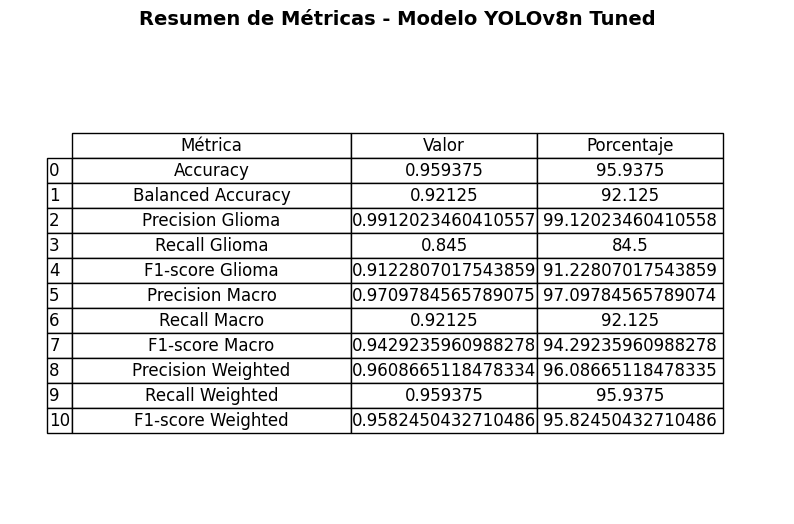

✅ Imagen guardada como: metricas_modelo_tuned.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas.plotting import table

# Configurar el estilo del gráfico para la tabla
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')

# Crear la tabla visual
tbl = table(ax, metrics_df, loc='center', cellLoc='center', colWidths=[0.3, 0.2, 0.2])
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1.2, 1.5)

# Título
plt.title('Resumen de Métricas - Modelo YOLOv8n Tuned', fontsize=14, fontweight='bold', pad=20)

# Guardar como PNG
output_file = 'metricas_modelo_tuned.png'
plt.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()

print(f'✅ Imagen guardada como: {output_file}')

# **PARA PRUEBA**

**DESCARGA DEPENDENCIAS Y DATASETS**

In [ ]:
# --- Instalar dependencias ---
!pip install ultralytics kaggle seaborn scikit-learn -q
print('✅ Dependencias instaladas')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.3 MB/s eta 0:00:00
✅ Dependencias instaladas


In [ ]:
# --- Descargar dataset ---
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d brain_tumor_raw
print('✅ Dataset descargado y descomprimido')

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:00<00:00, 229MB/s]

✅ Dataset descargado y descomprimido


In [ ]:
# =====================================================================
# EVALUACIÓN EN DATASET EXTERNO (sin reentrenar)
# Dataset: bilalakgz/brain-tumor-mri-dataset
# =====================================================================
!kaggle datasets download -d bilalakgz/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d external_raw
print('✅ Dataset externo descargado')

Dataset URL: https://www.kaggle.com/datasets/bilalakgz/brain-tumor-mri-dataset
License(s): MIT
brain-tumor-mri-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
✅ Dataset externo descargado


**Reestructurar Dataset**


In [ ]:
# --- Reestructurar a clasificación binaria ---
import shutil
import random
from pathlib import Path

random.seed(42)  # Reproducibilidad

raw          = Path('brain_tumor_raw')
train_src    = raw / 'Training'
test_src     = raw / 'Testing'
dest         = Path('brain_tumor_binary')

# Mapeo de 4 clases → 2 clases
BINARY_MAP = {
    'glioma':     'glioma',
    'meningioma': 'no_glioma',
    'notumor':    'no_glioma',
    'pituitary':  'no_glioma',
}

VAL_RATIO = 0.20  # 20% de Training → validación

# Crear estructura de carpetas
for split in ['train', 'val', 'test']:
    for cls in ['glioma', 'no_glioma']:
        (dest / split / cls).mkdir(parents=True, exist_ok=True)

def get_images(folder):
    exts = ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']
    imgs = []
    for ext in exts:
        imgs.extend(folder.glob(ext))
    return imgs

# Procesar Training → train + val
print('📂 Procesando Training → train / val (80/20)...')
for orig_cls, bin_cls in BINARY_MAP.items():
    src = train_src / orig_cls
    if not src.exists():
        print(f'  ⚠️  No encontrado: {src}')
        continue
    imgs = get_images(src)
    random.shuffle(imgs)
    cut = int(len(imgs) * (1 - VAL_RATIO))
    for img in imgs[:cut]:
        dst = dest / 'train' / bin_cls / f'{orig_cls}_{img.name}'
        shutil.copy2(img, dst)
    for img in imgs[cut:]:
        dst = dest / 'val' / bin_cls / f'{orig_cls}_{img.name}'
        shutil.copy2(img, dst)
    print(f'  {orig_cls:12s} → {bin_cls}: {cut} train | {len(imgs)-cut} val')

# Procesar Testing → test
print('\n📂 Procesando Testing → test...')
for orig_cls, bin_cls in BINARY_MAP.items():
    src = test_src / orig_cls
    if not src.exists():
        continue
    imgs = get_images(src)
    for img in imgs:
        dst = dest / 'test' / bin_cls / f'{orig_cls}_{img.name}'
        shutil.copy2(img, dst)
    print(f'  {orig_cls:12s} → {bin_cls}: {len(imgs)} test')

print('\n✅ Reestructuración completada')

📂 Procesando Training → train / val (80/20)...
  glioma       → glioma: 1120 train | 280 val
  meningioma   → no_glioma: 1120 train | 280 val
  notumor      → no_glioma: 1120 train | 280 val
  pituitary    → no_glioma: 1120 train | 280 val

📂 Procesando Testing → test...
  glioma       → glioma: 400 test
  meningioma   → no_glioma: 400 test
  notumor      → no_glioma: 400 test
  pituitary    → no_glioma: 400 test

✅ Reestructuración completada


**CARGAR MODELO**

In [ ]:
from google.colab import files
from ultralytics import YOLO
import shutil, os

print('📂 Seleccioná el archivo best.pt...')
uploaded = files.upload()

# Tomamos el nombre del archivo subido (por si no se llama exactamente "best.pt")
uploaded_filename = list(uploaded.keys())[0]

# Lo movemos a una ubicación fija y clara
os.makedirs('/content/best_model_weights', exist_ok=True)
shutil.move(uploaded_filename, '/content/best_model_weights/best.pt')

best_model = YOLO('/content/best_model_weights/best.pt')
BEST_MODEL = 'yolov8n'

print('✅ Modelo recargado correctamente desde el archivo subido')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
📂 Seleccioná el archivo best.pt...


Saving besttuned.pt to besttuned.pt
✅ Modelo recargado correctamente desde el archivo subido


**TEST**

In [ ]:
from ultralytics import YOLO
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# ============================================================
# CONFIGURACIÓN
# ============================================================

MODEL_PT = "/content/best_model_weights/best.pt"
DATA_PATH = "/content/external_binary"
SPLIT = "test"

CLASSES = ["glioma", "no_glioma"]
POSITIVE_CLASS = "glioma"

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ============================================================
# CARGAR MODELO
# ============================================================

model = YOLO(MODEL_PT)

print("Modelo cargado:", MODEL_PT)
print("Clases del modelo:", model.names)

# ============================================================
# CARGAR IMÁGENES DEL SPLIT
# ============================================================

data_dir = Path(DATA_PATH) / SPLIT

paths = []
y_true = []

for class_folder in data_dir.iterdir():
    if class_folder.is_dir():
        true_class = class_folder.name

        for img_path in class_folder.rglob("*"):
            if img_path.suffix.lower() in IMG_EXTS:
                paths.append(str(img_path))
                y_true.append(true_class)

print("\nImágenes evaluadas:", len(paths))

if len(paths) == 0:
    raise ValueError(f"No se encontraron imágenes en {data_dir}")

print("\nDistribución real:")
print(pd.Series(y_true).value_counts())

# ============================================================
# PREDICCIONES
# ============================================================

y_pred = []

for result in model.predict(
    source=paths,
    stream=True,
    verbose=False,
    save=False
):
    pred_idx = int(result.probs.top1)
    pred_class = model.names[pred_idx]
    y_pred.append(pred_class)

print("\nDistribución predicha:")
print(pd.Series(y_pred).value_counts())

# ============================================================
# MÉTRICAS GENERALES
# ============================================================

accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

# ============================================================
# MÉTRICAS ESPECÍFICAS PARA GLIOMA
# ============================================================

precision_glioma = precision_score(
    y_true, y_pred,
    pos_label=POSITIVE_CLASS,
    zero_division=0
)

recall_glioma = recall_score(
    y_true, y_pred,
    pos_label=POSITIVE_CLASS,
    zero_division=0
)

f1_glioma = f1_score(
    y_true, y_pred,
    pos_label=POSITIVE_CLASS,
    zero_division=0
)

# ============================================================
# MOSTRAR RESUMEN DE MÉTRICAS
# ============================================================

metrics_df = pd.DataFrame([
    {
        "Métrica": "Accuracy",
        "Valor": accuracy,
        "Porcentaje": accuracy * 100
    },
    {
        "Métrica": "Balanced Accuracy",
        "Valor": balanced_acc,
        "Porcentaje": balanced_acc * 100
    },
    {
        "Métrica": "Precision Glioma",
        "Valor": precision_glioma,
        "Porcentaje": precision_glioma * 100
    },
    {
        "Métrica": "Recall Glioma",
        "Valor": recall_glioma,
        "Porcentaje": recall_glioma * 100
    },
    {
        "Métrica": "F1-score Glioma",
        "Valor": f1_glioma,
        "Porcentaje": f1_glioma * 100
    },
    {
        "Métrica": "Precision Macro",
        "Valor": precision_macro,
        "Porcentaje": precision_macro * 100
    },
    {
        "Métrica": "Recall Macro",
        "Valor": recall_macro,
        "Porcentaje": recall_macro * 100
    },
    {
        "Métrica": "F1-score Macro",
        "Valor": f1_macro,
        "Porcentaje": f1_macro * 100
    },
    {
        "Métrica": "Precision Weighted",
        "Valor": precision_weighted,
        "Porcentaje": precision_weighted * 100
    },
    {
        "Métrica": "Recall Weighted",
        "Valor": recall_weighted,
        "Porcentaje": recall_weighted * 100
    },
    {
        "Métrica": "F1-score Weighted",
        "Valor": f1_weighted,
        "Porcentaje": f1_weighted * 100
    }
])

print("\n==============================")
print(" MÉTRICAS DEL MODELO")
print("==============================")
display(metrics_df)

# ============================================================
# REPORTE COMPLETO POR CLASE
# ============================================================

print("\n==============================")
print(" REPORTE DE CLASIFICACIÓN")
print("==============================")

print(
    classification_report(
        y_true,
        y_pred,
        labels=CLASSES,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# MATRIZ DE CONFUSIÓN
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=CLASSES
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Real {c}" for c in CLASSES],
    columns=[f"Predicho {c}" for c in CLASSES]
)

print("\n==============================")
print(" MATRIZ DE CONFUSIÓN")
print("==============================")
display(cm_df)

# ============================================================
# INTERPRETACIÓN DE ERRORES
# ============================================================

# Asumiendo orden: glioma / no_glioma
TP = cm[0, 0]  # glioma real predicho como glioma
FN = cm[0, 1]  # glioma real predicho como no_glioma
FP = cm[1, 0]  # no_glioma real predicho como glioma
TN = cm[1, 1]  # no_glioma real predicho como no_glioma

print("\n==============================")
print(" INTERPRETACIÓN BINARIA")
print("==============================")
print(f"Verdaderos Positivos Glioma (TP): {TP}")
print(f"Falsos Negativos Glioma (FN): {FN}")
print(f"Falsos Positivos Glioma (FP): {FP}")
print(f"Verdaderos Negativos No_Glioma (TN): {TN}")

print("\nInterpretación:")
print(f"- Recall glioma: {recall_glioma:.4f} → de todos los gliomas reales, detectó el {recall_glioma*100:.2f}%.")
print(f"- Precision glioma: {precision_glioma:.4f} → de todo lo que predijo como glioma, acertó el {precision_glioma*100:.2f}%.")
print(f"- F1-score glioma: {f1_glioma:.4f} → balance entre precision y recall para la clase glioma.")

Modelo cargado: /content/best_model_weights/best.pt
Clases del modelo: {0: 'glioma', 1: 'no_glioma'}

Imágenes evaluadas: 1600

Distribución real:
no_glioma    1200
glioma        400
Name: count, dtype: int64

Distribución predicha:
no_glioma    1259
glioma        341
Name: count, dtype: int64

 MÉTRICAS DEL MODELO


,Métrica,Valor,Porcentaje
0,Accuracy,0.959375,95.937500
1,Balanced Accuracy,0.921250,92.125000
2,Precision Glioma,0.991202,99.120235
3,Recall Glioma,0.845000,84.500000
4,F1-score Glioma,0.912281,91.228070
5,Precision Macro,0.970978,97.097846
6,Recall Macro,0.921250,92.125000
7,F1-score Macro,0.942924,94.292360
8,Precision Weighted,0.960867,96.086651
9,Recall Weighted,0.959375,95.937500



 REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

      glioma     0.9912    0.8450    0.9123       400
   no_glioma     0.9508    0.9975    0.9736      1200

    accuracy                         0.9594      1600
   macro avg     0.9710    0.9213    0.9429      1600
weighted avg     0.9609    0.9594    0.9582      1600


 MATRIZ DE CONFUSIÓN


,Predicho glioma,Predicho no_glioma
Real glioma,338,62
Real no_glioma,3,1197



 INTERPRETACIÓN BINARIA
Verdaderos Positivos Glioma (TP): 338
Falsos Negativos Glioma (FN): 62
Falsos Positivos Glioma (FP): 3
Verdaderos Negativos No_Glioma (TN): 1197

Interpretación:
- Recall glioma: 0.8450 → de todos los gliomas reales, detectó el 84.50%.
- Precision glioma: 0.9912 → de todo lo que predijo como glioma, acertó el 99.12%.
- F1-score glioma: 0.9123 → balance entre precision y recall para la clase glioma.
